In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import seaborn as sns
import umap
from sklearn.decomposition import PCA

In [ ]:
# Locate the repo from the current directory, so the notebook runs from anywhere.
HERE = Path.cwd()
ROOT = next((p for p in (HERE, *HERE.parents) if (p / "pyproject.toml").exists()), None)
if ROOT is None:
    raise RuntimeError(f"Start the notebook inside the repo: no pyproject.toml above {HERE}.")
DATA_DIR = ROOT / "data"

In [ ]:
sns.set_theme(style="white", context="notebook")

In [22]:
df = pd.read_csv(DATA_DIR / "arxiv_papers_preprocessed_v2.csv")
X = np.load(DATA_DIR / "arxiv_embeddings_v2.npy")

assert len(df) == len(X), "metadata and embeddings are out of sync"

print("Papers:", len(df), "| Embeddings:", X.shape)

Papers: 2000 | Embeddings: (2000, 768)


In [23]:
df.head()

,request_id,retrieved_at,domain,arxiv_id,title,summary,authors,primary_category,categories,published,updated,abs_url,pdf_url,text,text_clean
0,https://arxiv.org/api/Nn9ZAl7r/hPtw2SqI662/Ri9DWc,2026-10-30 05:02:17+00:00,cs,2610.40655v1,Elucidating the Design Space of LM Data Attrib...,Data attribution methods for Language Models (...,Steven Yu; Sheng-Yu Wang; Kimia Hamidieh; Anto...,cs.CL,cs.CL,2026-10-29 17:59:53+00:00,2026-10-29 17:59:53+00:00,http://arxiv.org/abs/2610.40655v1,https://arxiv.org/pdf/2610.40655v1,Elucidating the Design Space of LM Data Attrib...,elucidating design space lm data attribution d...
1,https://arxiv.org/api/Nn9ZAl7r/hPtw2SqI662/Ri9DWc,2026-10-30 05:02:17+00:00,cs,2610.40654v1,Propose-Filter-Release: Scaling Noise to Typic...,An estimator can be accurate and stable on typ...,Moshe Shenfeld; Eliad Tsfadia; Katrina Ligett,cs.LG,cs.LG,2026-10-29 17:59:49+00:00,2026-10-29 17:59:49+00:00,http://arxiv.org/abs/2610.40654v1,https://arxiv.org/pdf/2610.40654v1,Propose-Filter-Release: Scaling Noise to Typic...,propose filter release scaling noise typical s...
2,https://arxiv.org/api/Nn9ZAl7r/hPtw2SqI662/Ri9DWc,2026-10-30 05:02:17+00:00,cs,2610.40653v1,Micro-Edits: Computational Support for Fine-Sc...,"In film editing, every frame matters. While ma...",Nhan Tran; Hijung Valentina Shin; Abe Davis; M...,cs.HC,cs.HC; cs.CV,2026-10-29 17:59:49+00:00,2026-10-29 17:59:49+00:00,http://arxiv.org/abs/2610.40653v1,https://arxiv.org/pdf/2610.40653v1,Micro-Edits: Computational Support for Fine-Sc...,micro edits computational support fine scale e...
3,https://arxiv.org/api/Nn9ZAl7r/hPtw2SqI662/Ri9DWc,2026-10-30 05:02:17+00:00,cs,2610.40649v1,Rethinking Neural Thickets Without Weight Pert...,The Neural Thickets hypothesis posits that pre...,Nicolas Dufour; Elouan Gardès; Amil Dravid; Pa...,cs.LG,cs.LG; cs.AI; cs.CV,2026-10-29 17:59:29+00:00,2026-10-29 17:59:29+00:00,http://arxiv.org/abs/2610.40649v1,https://arxiv.org/pdf/2610.40649v1,Rethinking Neural Thickets Without Weight Pert...,rethinking neural thicket without weight pertu...
4,https://arxiv.org/api/Nn9ZAl7r/hPtw2SqI662/Ri9DWc,2026-10-30 05:02:17+00:00,cs,2610.40647v1,"Read, Allocate, Route: Role-Coupled Tokenizati...",Pixel-space generative Transformers typically ...,Jiongfan Yang; Weichen Fan; Haiwen Diao; Zhong...,cs.CV,cs.CV; cs.AI; cs.LG; cs.NE,2026-10-29 17:59:21+00:00,2026-10-29 17:59:21+00:00,http://arxiv.org/abs/2610.40647v1,https://arxiv.org/pdf/2610.40647v1,"Read, Allocate, Route: Role-Coupled Tokenizati...",read allocate route role coupled tokenization ...


In [24]:
def plot_category_counts(series, title):
    """Horizontal bars for how often each value occurs, rarest at the bottom."""
    counts = series.value_counts()
    share = counts / len(series) * 100
    names = [str(name) for name in counts.index]

    _, ax = plt.subplots(figsize=(8, max(3, 0.22 * len(counts))))
    ax.barh(names[::-1], counts.values[::-1], color="#4c72b0")
    ax.bar_label(
        ax.containers[0],
        labels=[f"{pct:.1f}%" for pct in share.values[::-1]],
        padding=2,
        fontsize=7,
    )

    ax.set_title(title, loc="left")
    ax.set_xlabel("Number of papers")
    ax.tick_params(labelsize=6 if len(counts) > 20 else 10)
    ax.margins(x=0.12)
    sns.despine()
    plt.tight_layout()
    plt.show()

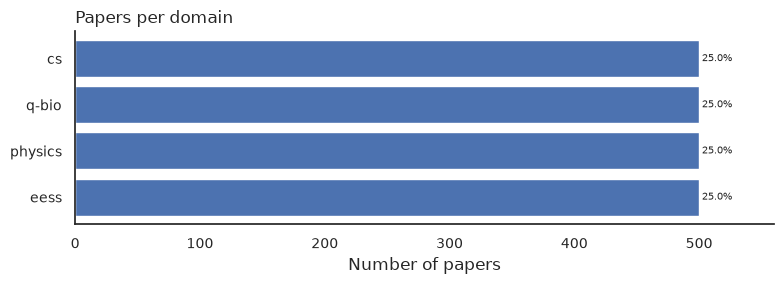

In [25]:
plot_category_counts(df["domain"], "Papers per domain")

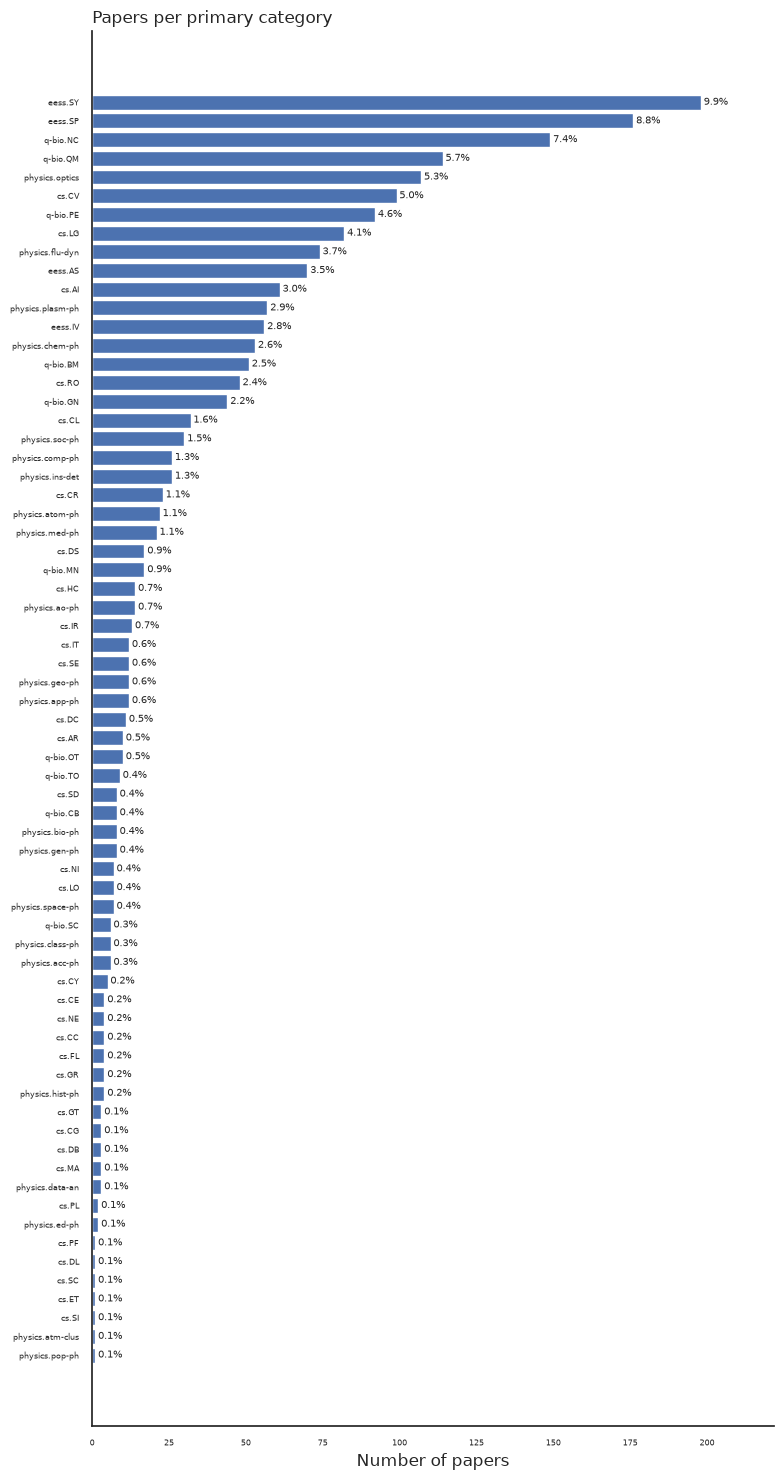

In [26]:
plot_category_counts(df["primary_category"], "Papers per primary category")

In [36]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

In [ ]:
print("Explained variance:", pca.explained_variance_ratio_)
print("Cumulative:", np.cumsum(pca.explained_variance_ratio_))

In [29]:
reducer = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.0,
    metric="cosine",
    random_state=42,
)
X_umap = reducer.fit_transform(X)


/home/abdelaziz/Documents/Arix-Research-Paper-Recommendation-System/.venv/lib64/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


In [30]:
reducer_3d = umap.UMAP(
    n_components=3,
    n_neighbors=15,
    min_dist=0.0,
    metric="cosine",
    random_state=42,
)
X_umap_3d = reducer_3d.fit_transform(X)


/home/abdelaziz/Documents/Arix-Research-Paper-Recommendation-System/.venv/lib64/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


In [32]:
def plot_embedding_2d(coords, title, xlabel, ylabel):
    """Scatter a 2D projection, one colour per domain. Coordinates are unlabelled."""
    plot_df = (
        df.assign(x=coords[:, 0], y=coords[:, 1])
        .sample(frac=1, random_state=42)
    )

    counts = plot_df["domain"].value_counts()
    plot_df["domain_n"] = plot_df["domain"].map(lambda d: f"{d} (n={counts[d]})")

    _, ax = plt.subplots(figsize=(10, 7))
    sns.scatterplot(
        data=plot_df,
        x="x", y="y",
        hue="domain_n",
        hue_order=sorted(plot_df["domain_n"].unique()),
        palette="tab10",
        s=8, alpha=0.6, linewidth=0, rasterized=True,
        ax=ax,
    )

    ax.set_title(title, loc="left", fontsize=13)
    ax.set(xlabel=xlabel, ylabel=ylabel, xticks=[], yticks=[])
    sns.move_legend(ax, "upper left", bbox_to_anchor=(1.02, 1), title="Domain", frameon=False)
    sns.despine()
    plt.tight_layout()
    plt.show()


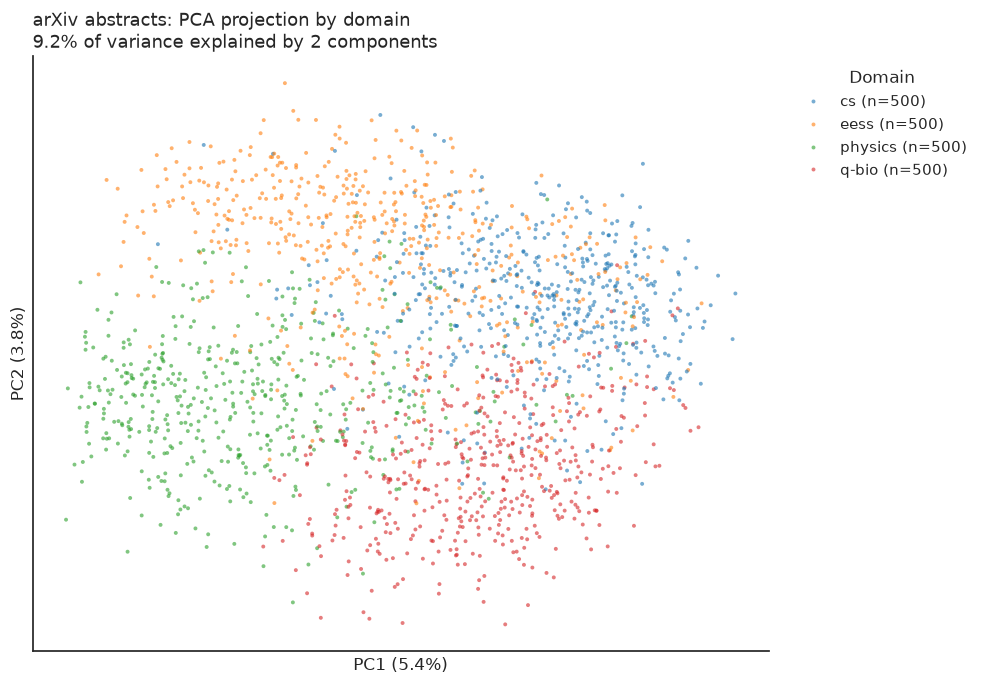

In [38]:
var = pca.explained_variance_ratio_ * 100
plot_embedding_2d(
    X_pca,
    "arXiv abstracts: PCA projection by domain\n"
    f"{var.sum():.1f}% of variance explained by 2 components",
    f"PC1 ({var[0]:.1f}%)",
    f"PC2 ({var[1]:.1f}%)",
)


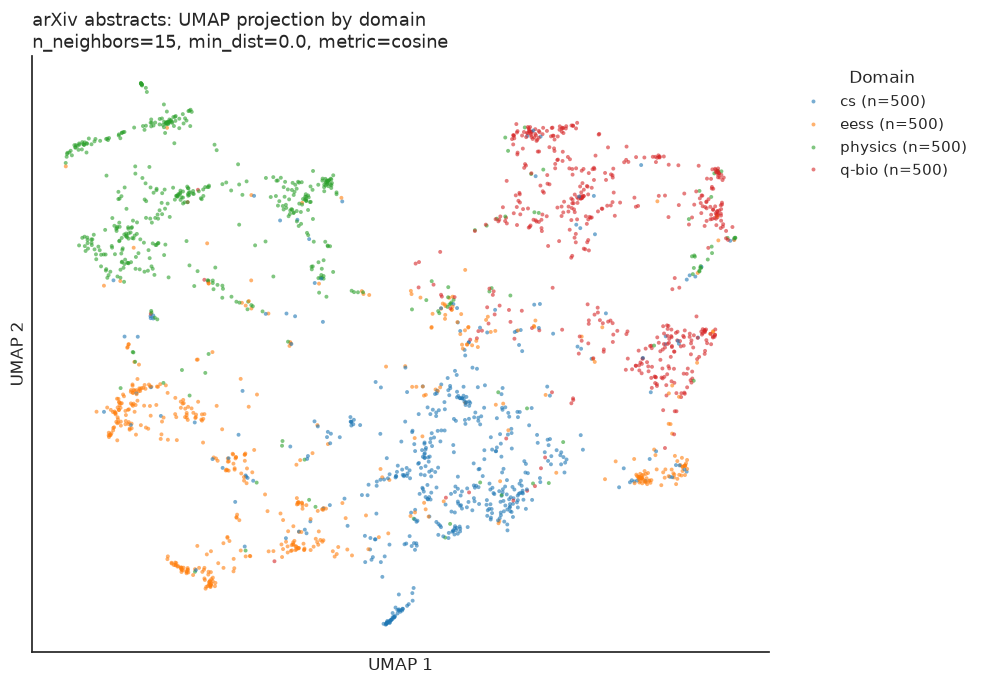

In [34]:
plot_embedding_2d(
    X_umap,
    "arXiv abstracts: UMAP projection by domain\n"
    "n_neighbors=15, min_dist=0.0, metric=cosine",
    "UMAP 1",
    "UMAP 2",
)


In [35]:
plot_df = (
    df.assign(umap_1=X_umap_3d[:, 0], umap_2=X_umap_3d[:, 1], umap_3=X_umap_3d[:, 2])
    .sample(frac=1, random_state=42)
)

counts = plot_df["domain"].value_counts()
plot_df["domain_n"] = plot_df["domain"].map(lambda d: f"{d} (n={counts[d]})")

fig = px.scatter_3d(
    plot_df,
    x="umap_1", y="umap_2", z="umap_3",
    color="domain_n",
    category_orders={"domain_n": sorted(plot_df["domain_n"].unique())},
    hover_name="title",
    hover_data={"primary_category": True, "umap_1": False, "umap_2": False, "umap_3": False},
    opacity=0.7,
    title="arXiv abstracts: 3D UMAP projection by domain<br>"
          "<sup>n_neighbors=15, min_dist=0.0, metric=cosine</sup>",
    width=950, height=750,
)
fig.update_traces(marker=dict(size=2.5))
fig.update_layout(
    legend_title_text="Domain",
    scene=dict(xaxis_title="UMAP 1", yaxis_title="UMAP 2", zaxis_title="UMAP 3"),
)
fig.show()
